In [1]:
import tensorflow as tf

In [2]:
from tensorflow.keras import layers,models
from tensorflow.keras.datasets import mnist

In [3]:
(train_images,train_labels),(test_images,test_labels)=mnist.load_data()

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [4]:
train_images=train_images.reshape((60000,28,28,1))
train_images=train_images.astype('float32')/255

In [5]:
model = models.Sequential([
    layers.Conv2D(32,(3,3),activation='relu',input_shape=(28,28,1)),
    layers.MaxPooling2D((2,2)),
    layers.Conv2D(64,(3,3),activation='relu'),
    layers.MaxPooling2D((2,2)),
    layers.Conv2D(64,(3,3),activation='relu'),
    layers.Flatten(),
    layers.Dense(64,activation='relu'),
    layers.Dense(10,activation='softmax')
])

/usr/local/lib/python3.10/dist-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [6]:
model.compile(optimizer='adam',loss='sparse_categorical_crossentropy',metrics=['accuracy'])

In [7]:
history = model.fit(train_images,train_labels,epochs=5,batch_size=64,validation_split=0.2)

Epoch 1/5
750/750 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.8378 - loss: 0.5175 - val_accuracy: 0.9794 - val_loss: 0.0689
Epoch 2/5
750/750 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9807 - loss: 0.0601 - val_accuracy: 0.9850 - val_loss: 0.0496
Epoch 3/5
750/750 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9891 - loss: 0.0376 - val_accuracy: 0.9855 - val_loss: 0.0447
Epoch 4/5
750/750 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9901 - loss: 0.0295 - val_accuracy: 0.9877 - val_loss: 0.0411
Epoch 5/5
750/750 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9917 - loss: 0.0259 - val_accuracy: 0.9897 - val_loss: 0.0422


In [8]:
test_loss,test_acc=model.evaluate(test_images,test_labels)

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9842 - loss: 9.4259


In [9]:
print(f'Test Accuracy:{test_acc}')

Test Accuracy:0.9894000291824341


In [10]:
Pred_test = model.predict(test_images)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


In [12]:
Pred_test

array([[0., 0., 0., ..., 1., 0., 0.],
       [0., 0., 1., ..., 0., 0., 0.],
       [0., 1., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.]], dtype=float32)

In [11]:
from sklearn.metrics import confusion_matrix

In [13]:
test_labels

array([7, 2, 1, ..., 4, 5, 6], dtype=uint8)

In [16]:
Predicted_labels = Pred_test.argmax(axis=1)

In [17]:
cm = confusion_matrix(test_labels,Predicted_labels)

Text(158.22222222222223, 0.5, 'Actual digits')

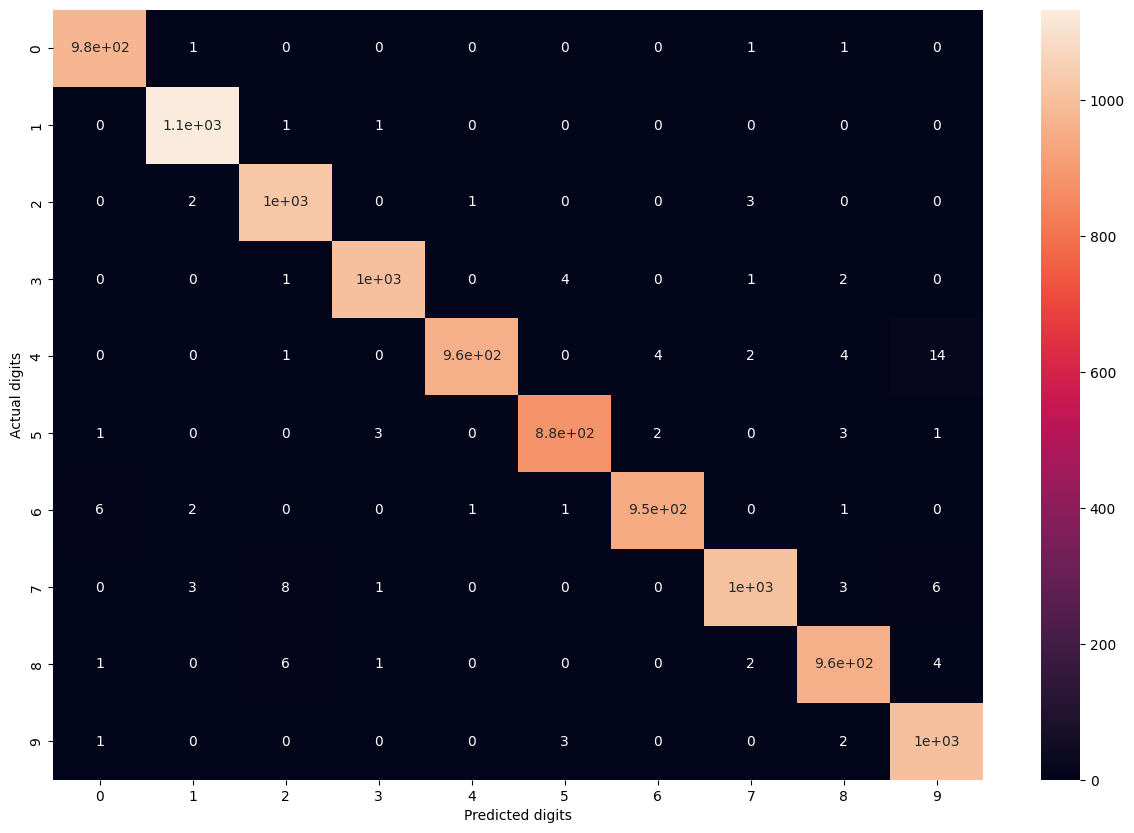

In [18]:
import seaborn as sn
import matplotlib.pyplot as plt
import seaborn as sn
plt.figure(figsize = (15,10))
sn.heatmap(cm,annot=True)
plt.xlabel('Predicted digits')
plt.ylabel('Actual digits')